In [1]:
print("Aegis is alive 🚀")

Aegis is alive 🚀


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
telemetry = pd.DataFrame({
    "cpu": [73],
    "memory": [81],
    "latency": [420],
    "error_rate": [7.2],
    "db_connections": [84]
})

telemetry

,cpu,memory,latency,error_rate,db_connections
0,73,81,420,7.2,84


In [4]:
cpu = np.random.normal(loc=50, scale=10, size=10)

cpu

array([37.92706685, 55.00058054, 48.99657705, 27.38149825, 30.52906098,
       47.39956026, 48.55355921, 47.26411935, 38.96996399, 56.89685907])

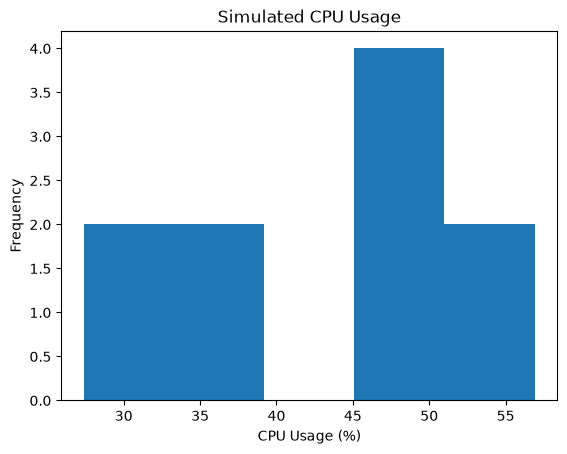

In [5]:
plt.hist(cpu, bins=5)
plt.xlabel("CPU Usage (%)")
plt.ylabel("Frequency")
plt.title("Simulated CPU Usage")
plt.show()

In [6]:
timestamps = pd.date_range(
    start="2026-01-01",
    periods=10000,
    freq="min"
)

timestamps[:10]

DatetimeIndex(['2026-01-01 00:00:00', '2026-01-01 00:01:00',
               '2026-01-01 00:02:00', '2026-01-01 00:03:00',
               '2026-01-01 00:04:00', '2026-01-01 00:05:00',
               '2026-01-01 00:06:00', '2026-01-01 00:07:00',
               '2026-01-01 00:08:00', '2026-01-01 00:09:00'],
              dtype='datetime64[us]', freq='min')

In [7]:
cpu = np.random.normal(
    loc=50,
    scale=8,
    size=len(timestamps)
)

cpu[:10]

array([48.63571603, 51.69206327, 53.89707946, 50.6689316 , 41.20167087,
       56.77292266, 48.33532831, 46.63591551, 56.72401   , 59.09101407])

In [8]:
len(timestamps), len(cpu)

(10000, 10000)

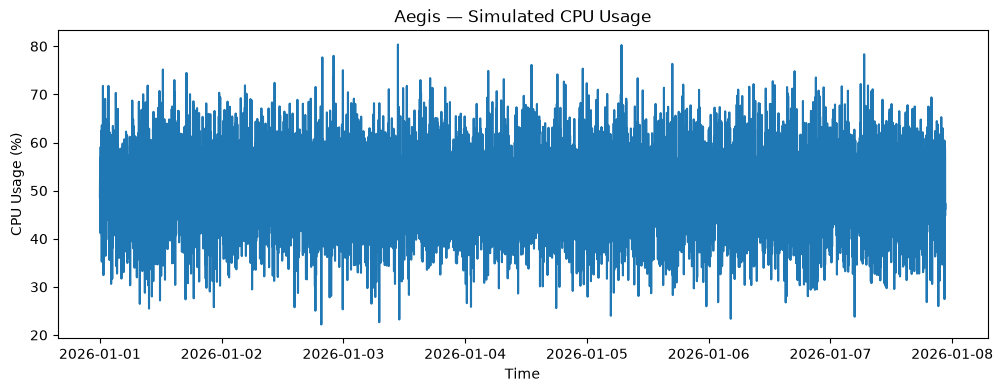

In [9]:
plt.figure(figsize=(12, 4))

plt.plot(timestamps, cpu)

plt.xlabel("Time")
plt.ylabel("CPU Usage (%)")
plt.title("Aegis — Simulated CPU Usage")

plt.show()

In [10]:
memory = np.random.normal(
    loc=60,
    scale=7,
    size=len(timestamps)
)

memory[:10]

array([61.64762093, 43.59584144, 74.16745112, 51.68233306, 56.48794117,
       71.8289758 , 58.14407838, 62.61546076, 49.79528105, 57.03293878])

In [11]:
len(memory)

10000

In [12]:
request_rate = np.random.normal(
    loc=120,
    scale=20,
    size=len(timestamps)
)

request_rate[:10]

array([143.24254855, 121.37086089, 127.45517744, 125.02521621,
       138.45934466, 130.21610314, 145.92002135,  83.6101343 ,
       116.04833044, 141.6332269 ])

In [13]:
request_rate = np.maximum(request_rate, 0)

request_rate[:10]

array([143.24254855, 121.37086089, 127.45517744, 125.02521621,
       138.45934466, 130.21610314, 145.92002135,  83.6101343 ,
       116.04833044, 141.6332269 ])

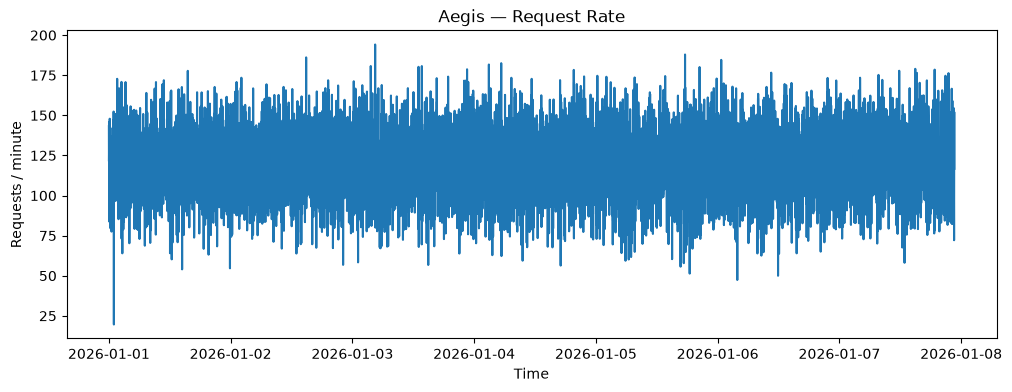

In [14]:
plt.figure(figsize=(12, 4))

plt.plot(timestamps, request_rate)

plt.xlabel("Time")
plt.ylabel("Requests / minute")
plt.title("Aegis — Request Rate")

plt.show()

In [15]:
latency = (
    100
    + 0.35 * (request_rate - 120)
    + np.random.normal(0, 10, len(timestamps))
)

latency[:10]

array([125.1816821 , 105.84994641,  88.33925689, 121.32101562,
       103.01485835, 102.49550686, 104.13590925,  86.79364493,
       103.24904436,  92.03938035])

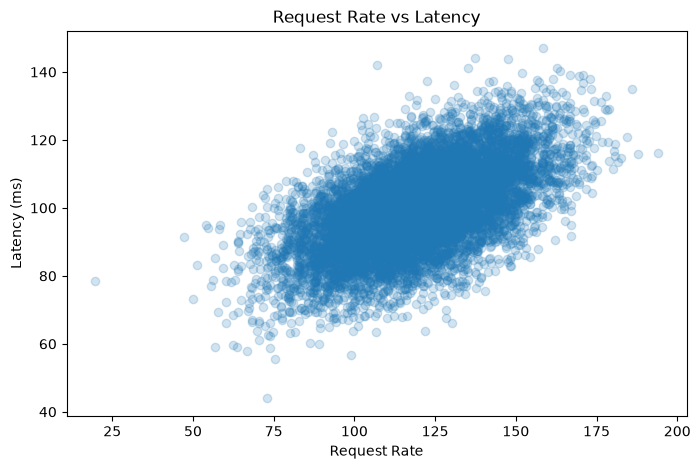

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(request_rate, latency, alpha=0.2)

plt.xlabel("Request Rate")
plt.ylabel("Latency (ms)")
plt.title("Request Rate vs Latency")

plt.show()

In [17]:
db_connections = (
    30
    + 0.25 * (request_rate - 120)
    + np.random.normal(0, 5, len(timestamps))
)

db_connections[:10]

array([33.67266698, 26.01921762, 31.24875639, 31.78714108, 33.6917179 ,
       26.43440329, 39.74411913, 26.32811186, 29.10020051, 31.53891143])

In [18]:
db_connections = np.maximum(db_connections, 0)

In [19]:
error_rate = (
    0.5
    + 0.02 * np.maximum(latency - 100, 0)
    + np.random.normal(0, 0.1, len(timestamps))
)

error_rate = np.maximum(error_rate, 0)

error_rate[:10]

array([0.81824675, 0.50285244, 0.50426998, 0.8822926 , 0.58177222,
       0.62436384, 0.72482111, 0.37737936, 0.48097227, 0.50350425])

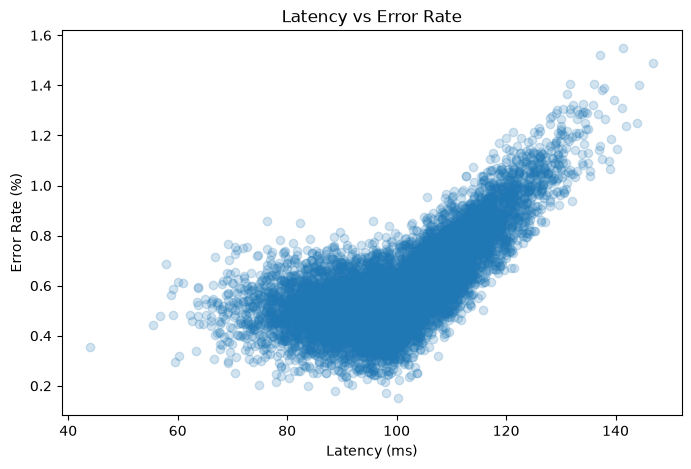

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(latency, error_rate, alpha=0.2)

plt.xlabel("Latency (ms)")
plt.ylabel("Error Rate (%)")
plt.title("Latency vs Error Rate")

plt.show()

In [21]:
telemetry = pd.DataFrame({
    "timestamp": timestamps,
    "cpu": cpu,
    "memory": memory,
    "request_rate": request_rate,
    "latency": latency,
    "error_rate": error_rate,
    "db_connections": db_connections
})

telemetry.head()

,timestamp,cpu,memory,request_rate,latency,error_rate,db_connections
0,2026-01-01 00:00:00,48.635716,61.647621,143.242549,125.181682,0.818247,33.672667
1,2026-01-01 00:01:00,51.692063,43.595841,121.370861,105.849946,0.502852,26.019218
2,2026-01-01 00:02:00,53.897079,74.167451,127.455177,88.339257,0.504270,31.248756
3,2026-01-01 00:03:00,50.668932,51.682333,125.025216,121.321016,0.882293,31.787141
4,2026-01-01 00:04:00,41.201671,56.487941,138.459345,103.014858,0.581772,33.691718


In [22]:
telemetry.shape

(10000, 7)

In [23]:
telemetry.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       10000 non-null  datetime64[us]
 1   cpu             10000 non-null  float64       
 2   memory          10000 non-null  float64       
 3   request_rate    10000 non-null  float64       
 4   latency         10000 non-null  float64       
 5   error_rate      10000 non-null  float64       
 6   db_connections  10000 non-null  float64       
dtypes: datetime64[us](1), float64(6)
memory usage: 547.0 KB


In [24]:
telemetry.describe()

,timestamp,cpu,memory,request_rate,latency,error_rate,db_connections
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2026-01-04 11:19:30,50.056572,59.969541,119.909633,100.061232,0.598928,30.020545
min,2026-01-01 00:00:00,22.184701,32.892887,19.593447,43.936596,0.151439,3.274040
25%,2026-01-02 17:39:45,44.601090,55.179536,106.543190,92.061315,0.479325,25.356650
50%,2026-01-04 11:19:30,50.116119,59.960384,120.031430,100.059900,0.568641,30.108125
75%,2026-01-06 04:59:15,55.370105,64.666024,133.340949,108.222490,0.690220,34.771430
max,2026-01-07 22:39:00,80.365804,88.977371,194.167059,146.922599,1.549223,56.458031
std,NaN,7.979340,7.089042,19.976315,12.228128,0.174920,7.103516


In [25]:
telemetry.corr(numeric_only=True)

,cpu,memory,request_rate,latency,error_rate,db_connections
cpu,1.000000,0.001261,-0.004048,-0.011639,-0.008148,-0.011586
memory,0.001261,1.000000,-0.005501,-0.007893,-0.000390,-0.004703
request_rate,-0.004048,-0.005501,1.000000,0.571918,0.399780,0.707284
latency,-0.011639,-0.007893,0.571918,1.000000,0.702849,0.396033
error_rate,-0.008148,-0.000390,0.399780,0.702849,1.000000,0.276593
db_connections,-0.011586,-0.004703,0.707284,0.396033,0.276593,1.000000


In [26]:
telemetry.isnull().sum()

timestamp         0
cpu               0
memory            0
request_rate      0
latency           0
error_rate        0
db_connections    0
dtype: int64

In [27]:
telemetry.nlargest(10, "latency")

,timestamp,cpu,memory,request_rate,latency,error_rate,db_connections
9784,2026-01-07 19:04:00,46.941790,50.890639,158.282866,146.922599,1.488942,40.143411
2386,2026-01-02 15:46:00,48.446277,58.275514,137.354105,144.196419,1.401601,24.907981
5893,2026-01-05 02:13:00,52.787427,64.135578,147.712297,143.838069,1.249543,39.412962
7075,2026-01-05 21:55:00,45.757040,66.438728,106.898090,141.933856,1.238816,27.580126
2638,2026-01-02 19:58:00,49.990663,55.886981,162.846834,141.305384,1.549223,49.213489
6663,2026-01-05 15:03:00,55.025595,56.845713,135.056378,141.139157,1.311428,29.772918
1271,2026-01-01 21:11:00,44.866438,52.228246,163.587246,140.246882,1.145757,41.322272
3159,2026-01-03 04:39:00,35.098003,55.959532,151.890519,139.731374,1.339767,36.053994
197,2026-01-01 03:17:00,39.877923,57.211886,170.742485,139.210470,1.185279,45.437164
3187,2026-01-03 05:07:00,49.070495,50.772585,166.924686,139.004361,1.065356,45.368580


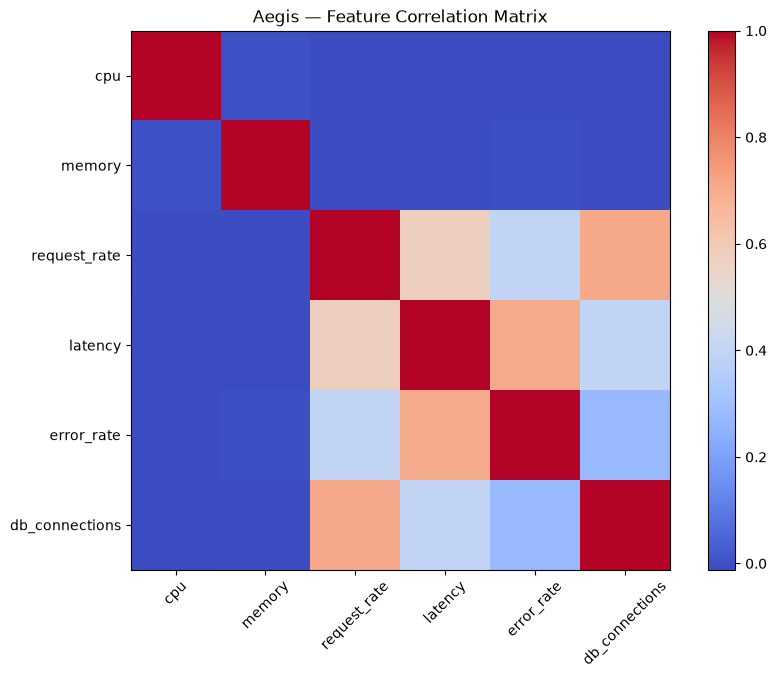

In [28]:
correlation = telemetry.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap="coolwarm")

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Aegis — Feature Correlation Matrix")

plt.show()

In [29]:
telemetry.to_csv("../data/telemetry_normal.csv", index=False)

In [30]:
incident_telemetry = telemetry.copy()

incident_telemetry.head()

,timestamp,cpu,memory,request_rate,latency,error_rate,db_connections
0,2026-01-01 00:00:00,48.635716,61.647621,143.242549,125.181682,0.818247,33.672667
1,2026-01-01 00:01:00,51.692063,43.595841,121.370861,105.849946,0.502852,26.019218
2,2026-01-01 00:02:00,53.897079,74.167451,127.455177,88.339257,0.504270,31.248756
3,2026-01-01 00:03:00,50.668932,51.682333,125.025216,121.321016,0.882293,31.787141
4,2026-01-01 00:04:00,41.201671,56.487941,138.459345,103.014858,0.581772,33.691718


In [31]:
incident_start = "2026-01-04 12:00"
incident_end = "2026-01-04 13:00"

In [32]:
incident_mask = (
    (incident_telemetry["timestamp"] >= incident_start)
    & (incident_telemetry["timestamp"] < incident_end)
)

incident_mask.sum()

np.int64(60)

In [33]:
incident_telemetry[incident_mask].head()

,timestamp,cpu,memory,request_rate,latency,error_rate,db_connections
5040,2026-01-04 12:00:00,55.343729,57.688444,118.190856,109.451225,0.558050,29.059776
5041,2026-01-04 12:01:00,43.643347,50.649891,117.924597,91.763641,0.495359,35.375481
5042,2026-01-04 12:02:00,45.775844,59.197821,106.149289,113.290141,0.643861,25.075712
5043,2026-01-04 12:03:00,47.000996,66.264362,125.399219,101.843333,0.631514,31.905256
5044,2026-01-04 12:04:00,55.497211,56.755542,107.260314,82.532996,0.470707,32.634346


In [34]:
incident_telemetry.loc[incident_mask, "request_rate"] *= 1.8

In [35]:
incident_telemetry.loc[incident_mask, "cpu"] += 25

In [36]:
incident_telemetry.loc[incident_mask, "memory"] += 12

In [37]:
incident_telemetry.loc[incident_mask, "db_connections"] *= 1.5

In [38]:
incident_telemetry.loc[incident_mask, "latency"] += 80

In [39]:
incident_telemetry.loc[incident_mask, "error_rate"] += 3

In [40]:
incident_telemetry.loc[incident_mask].describe()

,timestamp,cpu,memory,request_rate,latency,error_rate,db_connections
count,60,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,2026-01-04 12:29:30,76.218940,71.722865,215.923477,182.022723,3.586650,45.156187
min,2026-01-04 12:00:00,58.790534,58.781306,132.210951,152.345354,3.333258,23.608877
25%,2026-01-04 12:14:45,70.515717,68.374281,196.152537,176.214062,3.485578,38.108356
50%,2026-01-04 12:29:30,76.664085,70.909576,218.641148,181.918296,3.588870,44.235403
75%,2026-01-04 12:44:15,80.819754,75.775305,237.576480,189.318273,3.669727,51.386551
max,2026-01-04 12:59:00,92.315210,88.771703,269.924180,205.347456,4.049344,71.764848
std,NaN,7.966590,6.097097,29.056295,10.835683,0.145712,9.998273


In [41]:
incident_telemetry["is_incident"] = 0

incident_telemetry.loc[incident_mask, "is_incident"] = 1

In [42]:
incident_telemetry["is_incident"].value_counts()

is_incident
0    9940
1      60
Name: count, dtype: int64

In [43]:
incident_telemetry.to_csv(
    "../data/telemetry_with_incident.csv",
    index=False
)

In [44]:
incident_mask.sum()

np.int64(60)

In [45]:
incident_telemetry["is_incident"].value_counts()

is_incident
0    9940
1      60
Name: count, dtype: int64

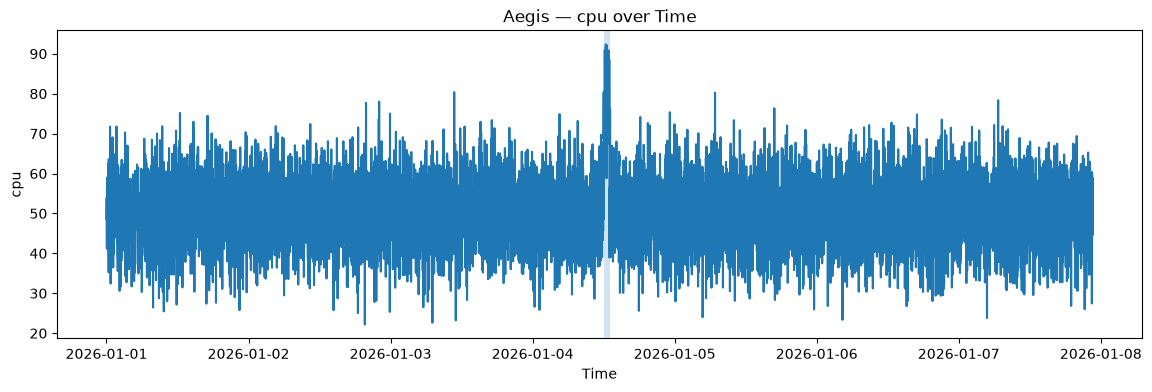

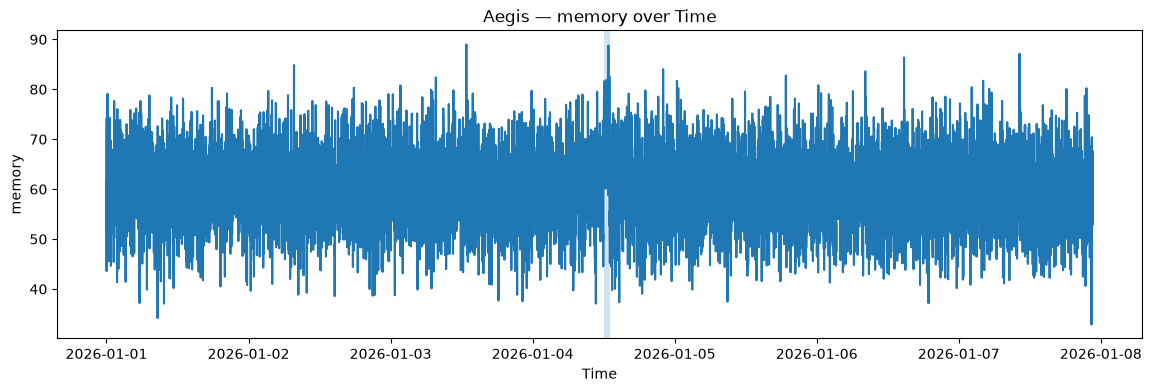

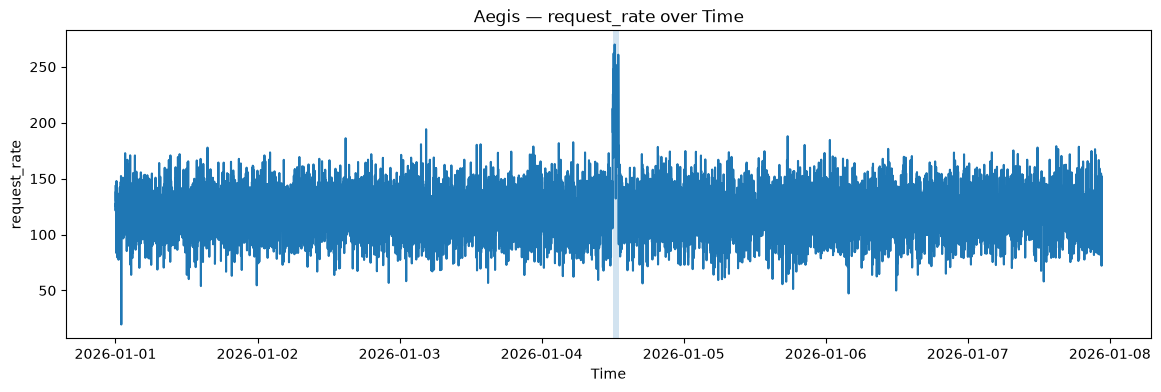

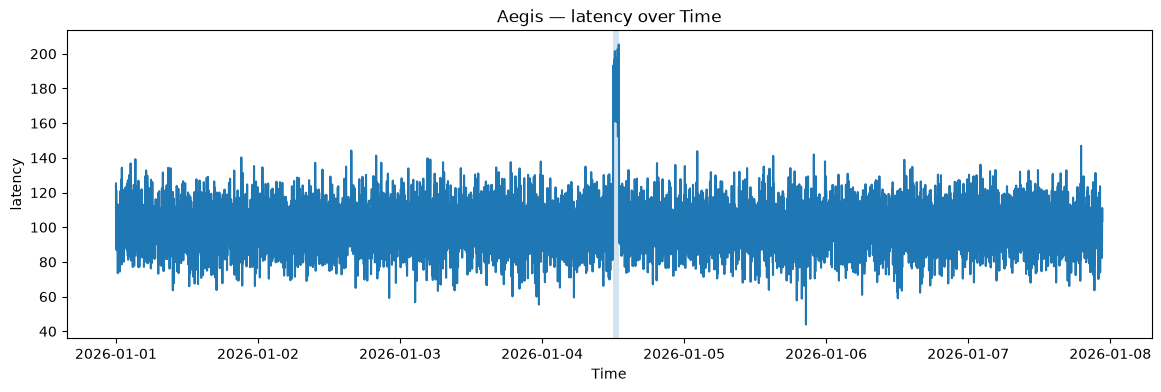

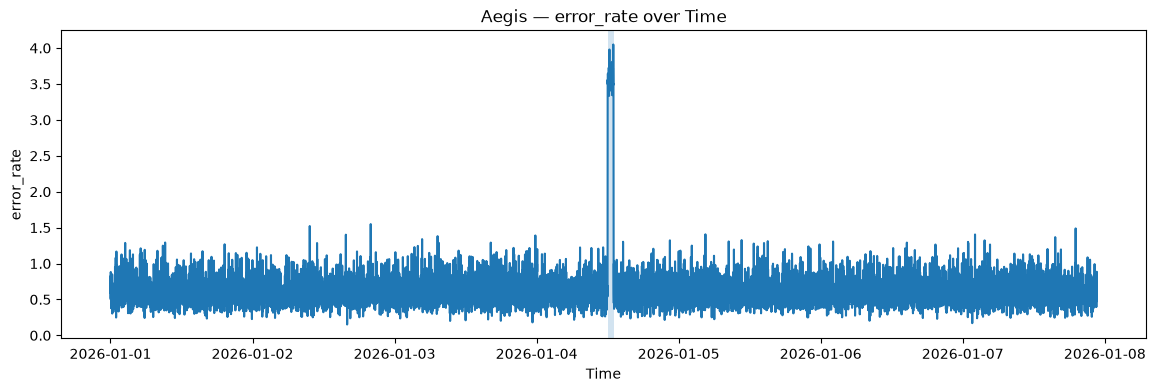

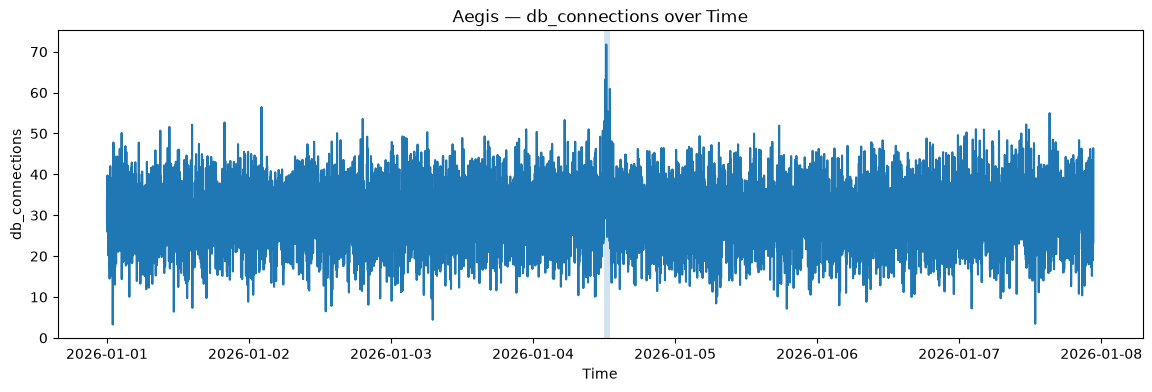

In [46]:
metrics = [
    "cpu",
    "memory",
    "request_rate",
    "latency",
    "error_rate",
    "db_connections"
]

for metric in metrics:

    plt.figure(figsize=(14, 4))

    plt.plot(
        incident_telemetry["timestamp"],
        incident_telemetry[metric]
    )

    plt.axvspan(
        pd.to_datetime(incident_start),
        pd.to_datetime(incident_end),
        alpha=0.2
    )

    plt.xlabel("Time")
    plt.ylabel(metric)
    plt.title(f"Aegis — {metric} over Time")

    plt.show()

In [47]:
features = [
    "cpu",
    "memory",
    "request_rate",
    "latency",
    "error_rate",
    "db_connections"
]

X = incident_telemetry[features]

In [48]:
y = incident_telemetry["is_incident"]

In [49]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 6)
y shape: (10000,)


In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [51]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (8000, 6)
Testing features: (2000, 6)
Training labels: (8000,)
Testing labels: (2000,)


In [52]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [53]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [54]:
y_pred = model.predict(X_test)

In [55]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1990
           1       1.00      1.00      1.00        10

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [56]:
print("Test incidents:", y_test.sum())
print("Train incidents:", y_train.sum())

Test incidents: 10
Train incidents: 50


In [57]:
split_index = int(len(incident_telemetry) * 0.8)

train_data = incident_telemetry.iloc[:split_index]
test_data = incident_telemetry.iloc[split_index:]

In [58]:
print("Training incidents:", train_data["is_incident"].sum())
print("Testing incidents:", test_data["is_incident"].sum())

Training incidents: 60
Testing incidents: 0


In [59]:
incident2_start = "2026-01-07 12:00"
incident2_end = "2026-01-07 13:00"

In [60]:
incident2_mask = (
    (incident_telemetry["timestamp"] >= incident2_start)
    & (incident_telemetry["timestamp"] < incident2_end)
)

incident2_mask.sum()

np.int64(60)

In [61]:
incident_telemetry["is_incident"].value_counts()

is_incident
0    9940
1      60
Name: count, dtype: int64

In [62]:
split_index = int(len(incident_telemetry) * 0.8)

train_data = incident_telemetry.iloc[:split_index]
test_data = incident_telemetry.iloc[split_index:]

In [63]:
print("Training incidents:", train_data["is_incident"].sum())
print("Testing incidents:", test_data["is_incident"].sum())

Training incidents: 60
Testing incidents: 0


In [64]:
print("First timestamp:", incident_telemetry["timestamp"].min())
print("Last timestamp:", incident_telemetry["timestamp"].max())

First timestamp: 2026-01-01 00:00:00
Last timestamp: 2026-01-07 22:39:00


In [65]:
print("Total incidents:", incident_telemetry["is_incident"].sum())

print(
    incident_telemetry[
        incident_telemetry["is_incident"] == 1
    ]["timestamp"].tail(10)
)

Total incidents: 60
5090   2026-01-04 12:50:00
5091   2026-01-04 12:51:00
5092   2026-01-04 12:52:00
5093   2026-01-04 12:53:00
5094   2026-01-04 12:54:00
5095   2026-01-04 12:55:00
5096   2026-01-04 12:56:00
5097   2026-01-04 12:57:00
5098   2026-01-04 12:58:00
5099   2026-01-04 12:59:00
Name: timestamp, dtype: datetime64[us]


In [66]:
incident2_mask.sum()

np.int64(60)

In [67]:
incident_telemetry.loc[
    incident2_mask,
    "is_incident"
] = 1

In [68]:
incident_telemetry["is_incident"].value_counts()

is_incident
0    9880
1     120
Name: count, dtype: int64

In [69]:
incident_telemetry.loc[
    incident2_mask,
    ["timestamp", "is_incident"]
].head()

,timestamp,is_incident
9360,2026-01-07 12:00:00,1
9361,2026-01-07 12:01:00,1
9362,2026-01-07 12:02:00,1
9363,2026-01-07 12:03:00,1
9364,2026-01-07 12:04:00,1


In [70]:
incident_telemetry.to_csv(
    "../data/telemetry_with_two_incidents.csv",
    index=False
)

In [71]:
split_index = int(len(incident_telemetry) * 0.8)

train_data = incident_telemetry.iloc[:split_index]
test_data = incident_telemetry.iloc[split_index:]

In [72]:
print("Training incidents:", train_data["is_incident"].sum())
print("Testing incidents:", test_data["is_incident"].sum())

Training incidents: 60
Testing incidents: 60


In [73]:
features = [
    "cpu",
    "memory",
    "request_rate",
    "latency",
    "error_rate",
    "db_connections"
]

X_train = train_data[features]
y_train = train_data["is_incident"]

X_test = test_data[features]
y_test = test_data["is_incident"]

In [74]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [75]:
y_pred = model.predict(X_test)

In [76]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1940
           1       0.00      0.00      0.00        60

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.94      0.97      0.96      2000



c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [77]:
incident_telemetry.groupby("is_incident")[features].mean()

,cpu,memory,request_rate,latency,error_rate,db_connections
is_incident,,,,,,
0,50.054154,59.981126,119.897692,100.045752,0.599115,30.015699
1,62.755657,65.015678,168.875765,141.335740,2.083512,37.945554


In [78]:
y_probability = model.predict_proba(X_test)

y_probability[:5]

array([[9.99999984e-01, 1.58794802e-08],
       [9.99999998e-01, 2.13991126e-09],
       [9.99999743e-01, 2.57404332e-07],
       [1.00000000e+00, 1.21847991e-12],
       [9.99999999e-01, 8.57768643e-10]])

In [79]:
incident_probability = y_probability[:, 1]

incident_probability[:10]

array([1.58794802e-08, 2.13991126e-09, 2.57404332e-07, 1.21847991e-12,
       8.57768643e-10, 5.24546886e-08, 3.70629009e-08, 1.09544320e-09,
       7.08749102e-08, 1.92783219e-09])

In [80]:
print("Maximum incident probability:", incident_probability.max())
print("Minimum incident probability:", incident_probability.min())
print("Average incident probability:", incident_probability.mean())

Maximum incident probability: 0.03729455084479215
Minimum incident probability: 7.603143337915616e-17
Average incident probability: 4.4402882146076977e-05


In [81]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1940    0]
 [  60    0]]


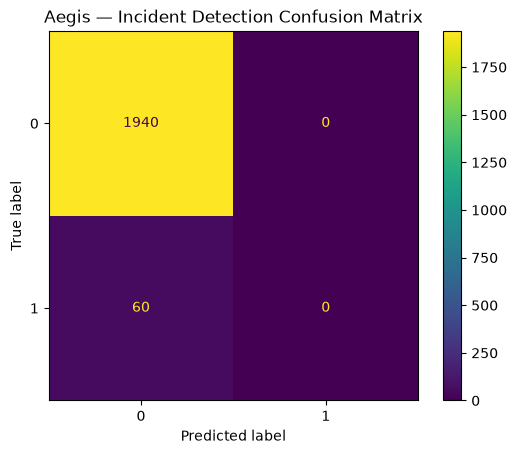

In [82]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.title("Aegis — Incident Detection Confusion Matrix")
plt.show()

In [83]:
from sklearn.metrics import recall_score

incident_recall = recall_score(y_test, y_pred)

print("Incident detection recall:", incident_recall)

Incident detection recall: 0.0


In [84]:
from sklearn.ensemble import RandomForestClassifier

balanced_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

balanced_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [85]:
balanced_pred = balanced_model.predict(X_test)

In [86]:
from sklearn.metrics import confusion_matrix

balanced_cm = confusion_matrix(y_test, balanced_pred)

print(balanced_cm)

[[1940    0]
 [  60    0]]


In [87]:
from sklearn.metrics import classification_report

print(classification_report(y_test, balanced_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1940
           1       0.00      0.00      0.00        60

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.94      0.97      0.96      2000



c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [88]:
from sklearn.ensemble import RandomForestClassifier

balanced_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_test)

In [89]:
from sklearn.metrics import classification_report

print(classification_report(y_test, balanced_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1940
           1       0.00      0.00      0.00        60

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.94      0.97      0.96      2000



c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [90]:
incident_telemetry.groupby("is_incident")[features].mean()

,cpu,memory,request_rate,latency,error_rate,db_connections
is_incident,,,,,,
0,50.054154,59.981126,119.897692,100.045752,0.599115,30.015699
1,62.755657,65.015678,168.875765,141.335740,2.083512,37.945554


In [91]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining incidents:")
print(y_train.value_counts())

print("\nTesting incidents:")
print(y_test.value_counts())

Training shape: (8000, 6)
Testing shape: (2000, 6)

Training incidents:
is_incident
0    7940
1      60
Name: count, dtype: int64

Testing incidents:
is_incident
0    1940
1      60
Name: count, dtype: int64


In [92]:
print("\nTraining feature means:")
print(train_data.groupby("is_incident")[features].mean())

print("\nTesting feature means:")
print(test_data.groupby("is_incident")[features].mean())


Training feature means:
                   cpu     memory  request_rate     latency  error_rate  \
is_incident                                                               
0            50.042014  60.035059    119.720030  100.000215    0.598666   
1            76.218940  71.722865    215.923477  182.022723    3.586650   

             db_connections  
is_incident                  
0                 29.923673  
1                 45.156187  

Testing feature means:
                   cpu     memory  request_rate     latency  error_rate  \
is_incident                                                               
0            50.103841  59.760391    120.624824  100.232123    0.600952   
1            49.292375  58.308492    121.828053  100.648757    0.580373   

             db_connections  
is_incident                  
0                 30.392342  
1                 30.734921  


In [93]:
two_incident = pd.read_csv("../data/telemetry_with_two_incidents.csv")

two_incident["timestamp"] = pd.to_datetime(two_incident["timestamp"])

print(two_incident.shape)

print("\nIncident count:")
print(two_incident["is_incident"].value_counts())

print("\nIncident feature means:")
print(two_incident.groupby("is_incident")[features].mean())

(10000, 8)

Incident count:
is_incident
0    9880
1     120
Name: count, dtype: int64

Incident feature means:
                   cpu     memory  request_rate     latency  error_rate  \
is_incident                                                               
0            50.054154  59.981126    119.897692  100.045752    0.599115   
1            62.755657  65.015678    168.875765  141.335740    2.083512   

             db_connections  
is_incident                  
0                 30.015699  
1                 37.945554  


In [94]:
from sklearn.model_selection import train_test_split

X = two_incident[features]
y = two_incident["is_incident"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining incidents:", y_train.sum())
print("Testing incidents:", y_test.sum())

Training samples: 8000
Testing samples: 2000

Training incidents: 96
Testing incidents: 24


In [95]:
balanced_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

balanced_model.fit(X_train, y_train)

balanced_pred = balanced_model.predict(X_test)

In [96]:
print(classification_report(y_test, balanced_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1976
           1       1.00      0.54      0.70        24

    accuracy                           0.99      2000
   macro avg       1.00      0.77      0.85      2000
weighted avg       0.99      0.99      0.99      2000



In [97]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get probability of incident (class 1)
incident_probability = balanced_model.predict_proba(X_test)[:, 1]

thresholds = [0.50, 0.40, 0.30, 0.20, 0.10]

for threshold in thresholds:

    threshold_pred = (incident_probability >= threshold).astype(int)

    precision = precision_score(y_test, threshold_pred, zero_division=0)
    recall = recall_score(y_test, threshold_pred, zero_division=0)
    f1 = f1_score(y_test, threshold_pred, zero_division=0)

    print(f"Threshold: {threshold}")
    print(f"  Precision: {precision:.2f}")
    print(f"  Recall:    {recall:.2f}")
    print(f"  F1-score:  {f1:.2f}")
    print()

Threshold: 0.5
  Precision: 1.00
  Recall:    0.54
  F1-score:  0.70

Threshold: 0.4
  Precision: 1.00
  Recall:    0.54
  F1-score:  0.70

Threshold: 0.3
  Precision: 0.87
  Recall:    0.54
  F1-score:  0.67

Threshold: 0.2
  Precision: 0.72
  Recall:    0.54
  F1-score:  0.62

Threshold: 0.1
  Precision: 0.29
  Recall:    0.54
  F1-score:  0.38



In [98]:
# Look at the model's probabilities for the actual incidents

incident_probs = incident_probability[y_test == 1]

print("Number of actual incidents:", len(incident_probs))
print("Minimum probability:", incident_probs.min())
print("Maximum probability:", incident_probs.max())
print("Average probability:", incident_probs.mean())

print("\nProbabilities of actual incidents:")
print(np.sort(incident_probs))

Number of actual incidents: 24
Minimum probability: 0.0
Maximum probability: 1.0
Average probability: 0.5494444444444444

Probabilities of actual incidents:
[0.         0.         0.         0.         0.         0.00666667
 0.00666667 0.02       0.02333333 0.07       0.08333333 0.99
 0.99       0.99666667 1.         1.         1.         1.
 1.         1.         1.         1.         1.         1.        ]


In [99]:
# Compare the actual test incidents with normal test data

normal_test = test_data[test_data["is_incident"] == 0]
incident_test = test_data[test_data["is_incident"] == 1]

print("NORMAL TEST DATA")
print(normal_test[features].describe().loc[["mean", "min", "max"]])

print("\nINCIDENT TEST DATA")
print(incident_test[features].describe().loc[["mean", "min", "max"]])

NORMAL TEST DATA
            cpu     memory  request_rate     latency  error_rate  \
mean  50.103841  59.760391    120.624824  100.232123    0.600952   
min   23.807154  32.892887     63.962477   62.261429    0.170088   
max   78.338765  87.136585    178.997405  146.922599    1.488942   

      db_connections  
mean       30.392342  
min         7.205478  
max        54.975636  

INCIDENT TEST DATA
            cpu     memory  request_rate     latency  error_rate  \
mean  49.292375  58.308492    121.828053  100.648757    0.580373   
min   29.553810  42.284206     58.060598   74.633764    0.319674   
max   67.993854  71.188374    156.637699  121.831436    1.113182   

      db_connections  
mean       30.734921  
min         3.438793  
max        47.660576  


In [100]:
# Compare training and testing incident distributions

print("TRAINING INCIDENTS")
print(train_data[train_data["is_incident"] == 1][features].describe())

print("\nTESTING INCIDENTS")
print(test_data[test_data["is_incident"] == 1][features].describe())

TRAINING INCIDENTS
             cpu     memory  request_rate     latency  error_rate  \
count  60.000000  60.000000     60.000000   60.000000   60.000000   
mean   76.218940  71.722865    215.923477  182.022723    3.586650   
std     7.966590   6.097097     29.056295   10.835683    0.145712   
min    58.790534  58.781306    132.210951  152.345354    3.333258   
25%    70.515717  68.374281    196.152537  176.214062    3.485578   
50%    76.664085  70.909576    218.641148  181.918296    3.588870   
75%    80.819754  75.775305    237.576480  189.318273    3.669727   
max    92.315210  88.771703    269.924180  205.347456    4.049344   

       db_connections  
count       60.000000  
mean        45.156187  
std          9.998273  
min         23.608877  
25%         38.108356  
50%         44.235403  
75%         51.386551  
max         71.764848  

TESTING INCIDENTS
             cpu     memory  request_rate     latency  error_rate  \
count  60.000000  60.000000     60.000000   60.000000  

In [101]:
# Feature importance from our balanced Random Forest

importance = balanced_model.feature_importances_

feature_importance = pd.DataFrame({
    "feature": features,
    "importance": importance
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
          feature  importance
4      error_rate    0.211435
2    request_rate    0.197134
3         latency    0.195334
0             cpu    0.139953
5  db_connections    0.128504
1          memory    0.127640


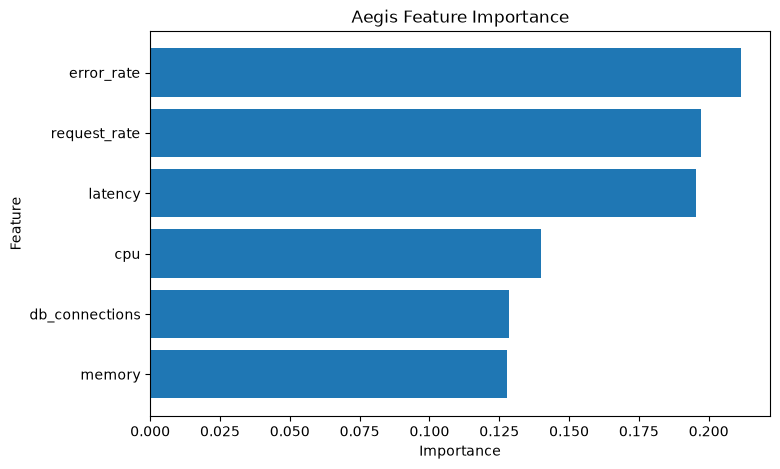

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Aegis Feature Importance")

plt.gca().invert_yaxis()

plt.show()

In [103]:
two_incident = pd.read_csv("../data/telemetry_with_two_incidents.csv")

print("Shape:", two_incident.shape)
print("\nIncident count:")
print(two_incident["is_incident"].value_counts())

Shape: (10000, 8)

Incident count:
is_incident
0    9880
1     120
Name: count, dtype: int64


In [104]:
print("\nIncident positions:")

incident_indices = two_incident.index[
    two_incident["is_incident"] == 1
]

print(incident_indices.tolist())


Incident positions:
[5040, 5041, 5042, 5043, 5044, 5045, 5046, 5047, 5048, 5049, 5050, 5051, 5052, 5053, 5054, 5055, 5056, 5057, 5058, 5059, 5060, 5061, 5062, 5063, 5064, 5065, 5066, 5067, 5068, 5069, 5070, 5071, 5072, 5073, 5074, 5075, 5076, 5077, 5078, 5079, 5080, 5081, 5082, 5083, 5084, 5085, 5086, 5087, 5088, 5089, 5090, 5091, 5092, 5093, 5094, 5095, 5096, 5097, 5098, 5099, 9360, 9361, 9362, 9363, 9364, 9365, 9366, 9367, 9368, 9369, 9370, 9371, 9372, 9373, 9374, 9375, 9376, 9377, 9378, 9379, 9380, 9381, 9382, 9383, 9384, 9385, 9386, 9387, 9388, 9389, 9390, 9391, 9392, 9393, 9394, 9395, 9396, 9397, 9398, 9399, 9400, 9401, 9402, 9403, 9404, 9405, 9406, 9407, 9408, 9409, 9410, 9411, 9412, 9413, 9414, 9415, 9416, 9417, 9418, 9419]


In [105]:
print("\nFeature means:")
print(
    two_incident.groupby("is_incident")[features].mean()
)


Feature means:
                   cpu     memory  request_rate     latency  error_rate  \
is_incident                                                               
0            50.054154  59.981126    119.897692  100.045752    0.599115   
1            62.755657  65.015678    168.875765  141.335740    2.083512   

             db_connections  
is_incident                  
0                 30.015699  
1                 37.945554  


In [106]:
# Prepare the two-incident dataset for Aegis

X_two = two_incident[features]

# Get incident probabilities
two_incident_proba = balanced_model.predict_proba(X_two)[:, 1]

# Convert probabilities into predictions
two_incident_pred = (two_incident_proba >= 0.5).astype(int)

print("Total observations:", len(two_incident))
print("Actual incidents:", two_incident["is_incident"].sum())
print("Predicted incidents:", two_incident_pred.sum())

Total observations: 10000
Actual incidents: 120
Predicted incidents: 109


In [107]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report:")
print(
    classification_report(
        two_incident["is_incident"],
        two_incident_pred
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        two_incident["is_incident"],
        two_incident_pred
    )
)

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      9880
           1       1.00      0.91      0.95       120

    accuracy                           1.00     10000
   macro avg       1.00      0.95      0.98     10000
weighted avg       1.00      1.00      1.00     10000


Confusion Matrix:
[[9880    0]
 [  11  109]]


In [108]:
def predict_incident(cpu, memory, request_rate, latency, error_rate, db_connections):
    
    data = np.array([[
        cpu,
        memory,
        request_rate,
        latency,
        error_rate,
        db_connections
    ]])
    
    probability = balanced_model.predict_proba(data)[0][1]
    
    prediction = int(probability >= 0.5)
    
    if prediction == 1:
        status = "INCIDENT DETECTED"
    else:
        status = "NORMAL"
    
    print(f"Prediction: {status}")
    print(f"Incident probability: {probability:.2%}")
    
    return prediction, probability

In [109]:
predict_incident(
    cpu=50,
    memory=60,
    request_rate=120,
    latency=100,
    error_rate=0.6,
    db_connections=30
)

Prediction: NORMAL
Incident probability: 0.67%


c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


(0, np.float64(0.006666666666666667))

In [110]:
predict_incident(
    cpu=80,
    memory=75,
    request_rate=220,
    latency=180,
    error_rate=3.5,
    db_connections=45
)

Prediction: INCIDENT DETECTED
Incident probability: 100.00%


c:\Users\ASUS\Desktop\Aegis\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


(1, np.float64(1.0))

In [111]:
def predict_incident(cpu, memory, request_rate, latency, error_rate, db_connections):
    
    data = pd.DataFrame([{
        "cpu": cpu,
        "memory": memory,
        "request_rate": request_rate,
        "latency": latency,
        "error_rate": error_rate,
        "db_connections": db_connections
    }])
    
    probability = balanced_model.predict_proba(data)[0][1]
    
    prediction = int(probability >= 0.5)
    
    if prediction == 1:
        status = "INCIDENT DETECTED"
    else:
        status = "NORMAL"
    
    print(f"Prediction: {status}")
    print(f"Incident probability: {probability:.2%}")
    
    return prediction, probability

In [112]:
predict_incident(
    cpu=80,
    memory=75,
    request_rate=220,
    latency=180,
    error_rate=3.5,
    db_connections=45
)

Prediction: INCIDENT DETECTED
Incident probability: 100.00%


(1, np.float64(1.0))

In [113]:
predict_incident(
    cpu=50,
    memory=60,
    request_rate=120,
    latency=100,
    error_rate=0.6,
    db_connections=30
)

Prediction: NORMAL
Incident probability: 0.67%


(0, np.float64(0.006666666666666667))

In [114]:
import joblib

joblib.dump(balanced_model, "../src/aegis_model.pkl")

print("Model saved successfully!")

Model saved successfully!
